In [1]:
import sys
sys.path.insert(0, "../src")
import pet

print(round(float(pet.extraterrestrial_radiation(-20, 246)), 1), "Ra (FAO-56 Example 8: 32.2)")
print(round(float(pet.daylength(-20, 246)), 1), "N (FAO-56 Example 9: about 11.7)")

32.2 Ra (FAO-56 Example 8: 32.2)
11.6 N (FAO-56 Example 9: about 11.7)


In [2]:
import numpy as np
import xarray as xr

proc = "../data/processed"
ds = xr.open_dataset(f"{proc}/marathwada_monthly_025.nc")

I = pet.heat_index(ds["tmean"])
pet_th = pet.thornthwaite(ds["tmean"], I=I)
pet_hg = pet.hargreaves(ds["tmax"], ds["tmin"])
print(f"heat index I: {float(I.min()):.0f} to {float(I.max()):.0f}")

heat index I: 145 to 159


In [3]:
inside = ds["pr"].notnull().any("time")
for name, p in [("Thornthwaite", pet_th), ("Hargreaves", pet_hg)]:
    print(name, int((p.isnull() & inside).sum()), "missing cell-months inside (expect 0),",
          int((p < 0).sum()), "negative (expect 0)")

J, _ = pet.month_terms(ds.time)
N = pet.daylength(ds.lat, J).groupby("time.month").mean().mean("lat")
print("day length (h), Jan to Dec:", N.round(1).values)

w = np.cos(np.deg2rad(ds.lat))
reg = xr.Dataset({"pr": ds["pr"], "pet_th": pet_th, "pet_hg": pet_hg}).weighted(w).mean(("lat", "lon"))

clim = reg.groupby("time.month").mean()
clim["d_th"] = clim["pr"] - clim["pet_th"]
clim["d_hg"] = clim["pr"] - clim["pet_hg"]
print(clim.to_dataframe().round(0))

annual = reg.resample(time="YS").sum().to_dataframe()
annual["d_th"] = annual["pr"] - annual["pet_th"]
annual["d_hg"] = annual["pr"] - annual["pet_hg"]
print(annual.describe().round(0))

Thornthwaite 0 missing cell-months inside (expect 0), 0 negative (expect 0)
Hargreaves 0 missing cell-months inside (expect 0), 0 negative (expect 0)
day length (h), Jan to Dec: [11.  11.4 11.9 12.4 12.9 13.1 13.  12.6 12.1 11.5 11.1 10.9]
          pr  pet_th  pet_hg   d_th   d_hg
month                                     
1        5.0    62.0   127.0  -57.0 -123.0
2        3.0    86.0   143.0  -84.0 -140.0
3        9.0   170.0   193.0 -161.0 -184.0
4        8.0   268.0   214.0 -260.0 -207.0
5       14.0   342.0   226.0 -327.0 -211.0
6      138.0   228.0   179.0  -90.0  -40.0
7      192.0   158.0   147.0   34.0   44.0
8      179.0   136.0   138.0   43.0   41.0
9      168.0   134.0   137.0   34.0   31.0
10      78.0   125.0   145.0  -47.0  -67.0
11      14.0    81.0   125.0  -66.0 -111.0
12       5.0    59.0   120.0  -54.0 -115.0
           pr  pet_th  pet_hg    d_th    d_hg
count    43.0    43.0    43.0    43.0    43.0
mean    813.0  1848.0  1895.0 -1035.0 -1082.0
std     194.0    92.

In [4]:
out = xr.Dataset({"pet_th": pet_th, "pet_hg": pet_hg, "heat_index": I})
out["pet_th"].attrs.update(units="mm/month", long_name="PET, Thornthwaite (1948) as in Vicente-Serrano et al. (2010)")
out["pet_hg"].attrs.update(units="mm/month", long_name="reference ET, Hargreaves and Samani (1985), FAO-56 eq. 52")
out["heat_index"].attrs["long_name"] = "Thornthwaite heat index I from the 1981-2023 monthly climatology"
out.to_netcdf(f"{proc}/marathwada_pet_025.nc")

reg.to_dataframe().round(2).to_csv("../outputs/tables/marathwada_pet_regional.csv")

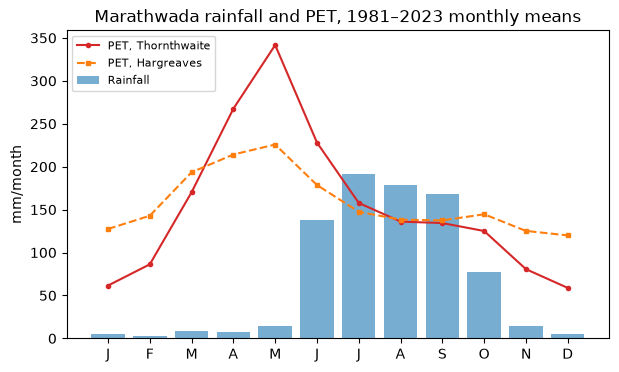

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(clim.month, clim.pr, color="tab:blue", alpha=0.6, label="Rainfall")
ax.plot(clim.month, clim.pet_th, "o-", color="tab:red", ms=3, label="PET, Thornthwaite")
ax.plot(clim.month, clim.pet_hg, "s--", color="tab:orange", ms=3, label="PET, Hargreaves")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("mm/month")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Marathwada rainfall and PET, 1981–2023 monthly means")
fig.savefig("../outputs/figures/fig03_pet_climatology.png", dpi=300, bbox_inches="tight")